# Solución del ejercicio 3: parte computacional

*El enunciado está en `ejercicios_3_y_4_transcripcion.md` y la parte analítica en `soluciones_parcial.pdf`.*

De la parte analítica usamos el problema de valor inicial al que se reduce la ecuación de ondas, cuya solución es la referencia de comparación,
$$
a''+\kappa^2a=0,\quad a(0)=1,\quad a'(0)=v_0=\sqrt{2\pi}
\Rightarrow
a(t)=\cos(\omega t)+\frac{v_0}{\omega}\sin(\omega t),\qquad \omega=\kappa=\sqrt2\,\pi,
$$
y el residuo físico y la función de pérdida,
$$
r_\theta=a_\theta''+\kappa^2a_\theta,
\qquad
\mathcal L(\theta)=\frac{1}{N_c}\sum_{k=1}^{N_c}r_\theta(t_k)^2+\lambda_0\left[a_\theta(0)-1\right]^2+\lambda_1\left[a_\theta'(0)-v_0\right]^2.
$$

La implementación está en el paquete `pinn_membrana`:

| Módulo | Contenido |
|---|---|
| `fisica.py` | `MembranaCuadrada`: solución analítica $a(t)$ y energía mecánica. |
| `arquitecturas.py` | `ModeloA`, `ModeloB`: $a_\theta$, $a_\theta'$ y $a_\theta''$ con las expresiones de la parte b), y su jacobiano respecto a $\theta$. |
| `perdida.py` | `PerdidaPINN`: residuo $r_\theta$ y pérdida $\mathcal L(\theta)$, con su gradiente. |
| `optimizacion.py` | `Adam`, `EntrenadorPINN`: minimización Adam $\to$ L-BFGS con multi-inicio. |
| `analisis.py` | `EvaluadorSolucion`: errores de aproximación y energía. |
| `graficos.py` | Figuras. |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pinn_membrana import MembranaCuadrada, ModeloA, ModeloB, PerdidaPINN, EntrenadorPINN, EvaluadorSolucion, tabla
from pinn_membrana import graficos

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------------- Configuración ---------------- #
V0 = np.sqrt(2 * np.pi)   # a'(0)
T = 3.0                   # ventana de colocación [0, T] (~2.1 periodos)
N_C = 200                 # puntos de colocación
LAMBDA_0 = LAMBDA_1 = 1.0
N_INICIOS = 20
T_PRUEBA = np.linspace(0, 2 * T, 4001)   # incluye extrapolación a (T, 2T]

membrana = MembranaCuadrada(u0=1.0, v0=V0)
t_col = np.linspace(0, T, N_C)
R, delta = membrana.amplitud_total, membrana.fase
print(f"omega = kappa = {membrana.omega:.6f},  periodo = {membrana.periodo:.6f}")
print(f"a(t) = cos(omega t) + (v0/omega) sin(omega t) = R sin(omega t + delta),  R = {R:.6f},  delta = {delta:.6f}")

omega = kappa = 4.442883,  periodo = 1.414214
a(t) = cos(omega t) + (v0/omega) sin(omega t) = R sin(omega t + delta),  R = 1.148177,  delta = 1.057124


### 1. Implementación y minimización de la pérdida

Cada modelo implementa $a_\theta$, $a_\theta'$ y $a_\theta''$ con las expresiones de la parte b), y `PerdidaPINN` evalúa $\mathcal L(\theta)$ con $N_c=200$ puntos de colocación uniformes en $[0,T]$, $T=3$ (unos $2.1$ periodos), y $\lambda_0=\lambda_1=1$. El gradiente $\nabla_\theta\mathcal L$ se calcula de forma exacta: en el Modelo A con el jacobiano analítico, y en el Modelo B por diferenciación de paso complejo,
$$
\frac{\partial r}{\partial\theta_m}=\frac{\operatorname{Im}\,r(\theta+ih\,\mathbf e_m)}{h},\qquad h=10^{-30},
$$
que no tiene error de cancelación.

Para minimizar usamos primero Adam ($2000$ iteraciones, tasa $10^{-2}$), que es robusto lejos del mínimo, y luego L-BFGS, que converge de forma superlineal cerca de él. Como $\mathcal L$ no es convexa en las frecuencias, repetimos el proceso desde $20$ inicializaciones aleatorias ($\omega\sim\mathcal U(0.5,10)$, $b\sim\mathcal U(-\pi,\pi)$, amplitudes $\sim\mathcal U(-2,2)$) y conservamos la de menor pérdida.

Modelo A: mejor L = 9.085e-30;  inicios con L < 1e-6: 20/20;  resto: []
         A_1 = -0.0000000000
     omega_1 =  3.7786639112
         b_1 = -1.8578487130
         A_2 = -1.1481767661
     omega_2 =  4.4428829382
         b_2 =  4.1987169649
    componentes: {'fisica': '4.11e-30', 'ci_posicion': '4.93e-32', 'ci_velocidad': '4.93e-30', 'total': '9.09e-30'}
Modelo B: mejor L = 1.063e-07;  inicios con L < 1e-6: 14/20;  resto: [3.66 4.3  4.3  4.31 7.08 7.08]
     omega_1 =  4.4428863985
         b_1 =  1.0571183341
     omega_2 = -0.0078100420
         b_2 =  3.1415926598
           A =  147.0146065558
    componentes: {'fisica': '1.06e-07', 'ci_posicion': '5.92e-14', 'ci_velocidad': '8.98e-16', 'total': '1.06e-07'}

Modelo B: A omega_2 cos(b_2) = 1.148190  (R = 1.148177),  omega_1 - kappa = 3.46e-06


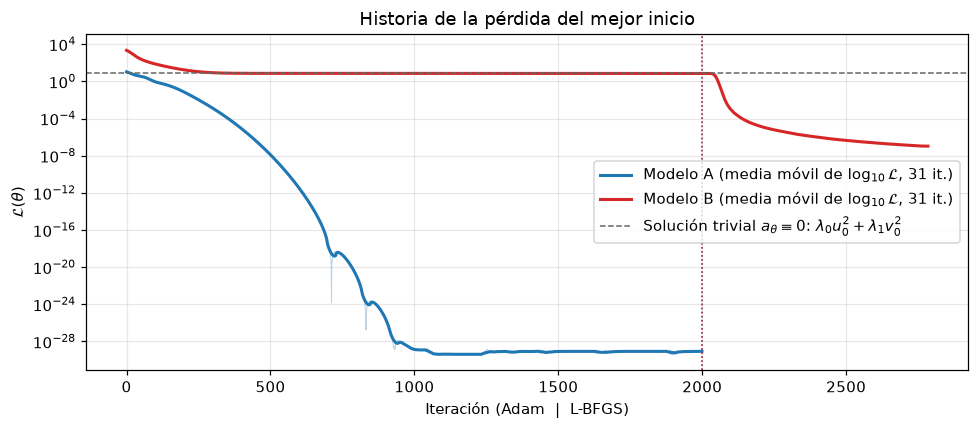

In [2]:
modelos = {"Modelo A": ModeloA(), "Modelo B": ModeloB()}
perdidas = {n: PerdidaPINN(m, membrana, t_col, LAMBDA_0, LAMBDA_1) for n, m in modelos.items()}
entrenadores = {n: EntrenadorPINN(p, iter_adam=2000, iter_lbfgs=5000) for n, p in perdidas.items()}

multi = {n: e.multiinicio(N_INICIOS, semilla=0) for n, e in entrenadores.items()}
mejores = {n: r[0] for n, r in multi.items()}
evaluadores = {n: EvaluadorSolucion(modelos[n], r.theta, membrana) for n, r in mejores.items()}

for n, r in mejores.items():
    L = np.array([x.perdida for x in multi[n]])
    print(f"{n}: mejor L = {r.perdida:.3e};  inicios con L < 1e-6: {np.sum(L < 1e-6)}/{L.size};  "
          f"resto: {np.array2string(np.sort(L[L >= 1e-6]), precision=2)}")
    for k, v in modelos[n].describir(r.theta).items():
        print(f"    {k:>8} = {v: .10f}")
    print("    componentes:", {k: f"{v:.2e}" for k, v in perdidas[n].componentes(r.theta).items()})

w1, b1, w2, b2, A = mejores["Modelo B"].theta
print(f"\nModelo B: A omega_2 cos(b_2) = {A * w2 * np.cos(b2):.6f}  (R = {R:.6f}),  omega_1 - kappa = {w1 - membrana.omega:.2e}")

graficos.historias_perdida(mejores, perdidas["Modelo B"].perdida_trivial)
plt.show()

**Análisis de la minimización.**

Para el Modelo A, los $20$ inicios terminan con $\mathcal L<10^{-16}$, y el mejor con $\mathcal L\approx9\times10^{-30}$, que es el nivel de redondeo. En él, una neurona tiene $\omega_2=\kappa$ y $|A_2|=R$, y la otra está apagada ($A_1\sim10^{-16}$). Esto es porque, si $\omega_1\neq\kappa$, la única forma de anular $r_A=\sum_jA_j(\kappa^2-\omega_j^2)\sin(\omega_jt+b_j)$ es $A_1=0$. Así, con $A_2=-R$ y $b_2=\delta+\pi$,
$$
a_\theta(t)=-R\sin(\omega t+\delta+\pi)
\Rightarrow
\boxed{a_\theta(t)=R\sin(\omega t+\delta)=a(t)}
$$
Es decir, el entrenamiento recupera exactamente la solución analítica.

Por su parte, en el Modelo B, $14$ de los $20$ inicios llegan a $\mathcal L\sim10^{-7}$ y $6$ quedan en mínimos locales con $\mathcal L\approx3.7$–$7.1$. El mejor tiene $\omega_1\approx\kappa$, $b_2\approx\pi$, $\omega_2\approx-0.008$ y $A\approx147$, con $A\,\omega_2\cos b_2=1.14819$, igual a $R$ en cinco cifras. Entonces, la red opera en el régimen
$$
A\sin(\omega_2h_1+b_2)\approx A\,\omega_2\cos b_2\,h_1=R\,h_1,
$$
que sólo es exacto en el límite $\omega_2\to0$, $A\to\infty$ (sección 3).

Ahora, en la historia de la pérdida vemos que, en el Modelo A, Adam desciende en unas $1000$ iteraciones hasta el piso de redondeo, $\mathcal L\sim10^{-28}$. La curva tenue cae bruscamente cada vez que los parámetros cruzan el mínimo, por la oscilación amortiguada que produce el momento de Adam, y la media móvil muestra la tendencia. En el Modelo B, en cambio, Adam queda en una meseta exactamente sobre la línea discontinua
$$
\mathcal L=\lambda_0u_0^2+\lambda_1v_0^2=1+2\pi\approx7.28,
$$
que es la pérdida de la solución trivial $a_\theta\approx0$ ($A\approx7\times10^{-4}$): el residuo es casi nulo y sólo pagan las condiciones iniciales. Como $a_\theta=A\sin z$, las derivadas respecto a $\omega_1,b_1,\omega_2,b_2$ son proporcionales a $A$, y por eso Adam queda varado. Por último, L-BFGS, que usa información de curvatura, escapa de la meseta y desciende hasta $10^{-7}$.

### 2. Comparación con la solución analítica

Ahora, evaluamos en $[0,2T]$: el intervalo $[0,T]$ (sombreado) es la ventana de colocación y $(T,2T]$ mide la capacidad de extrapolación. Comparamos la amplitud $a_\theta(t)$ y el desplazamiento $U_\theta(x,y,t)$ de la membrana.

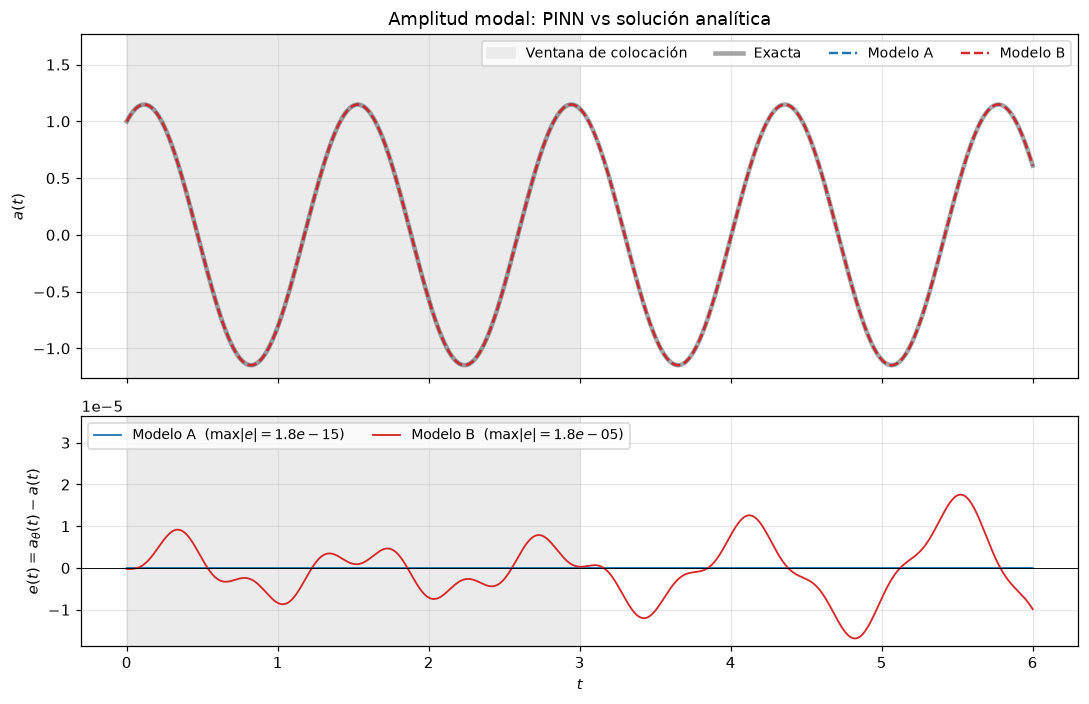

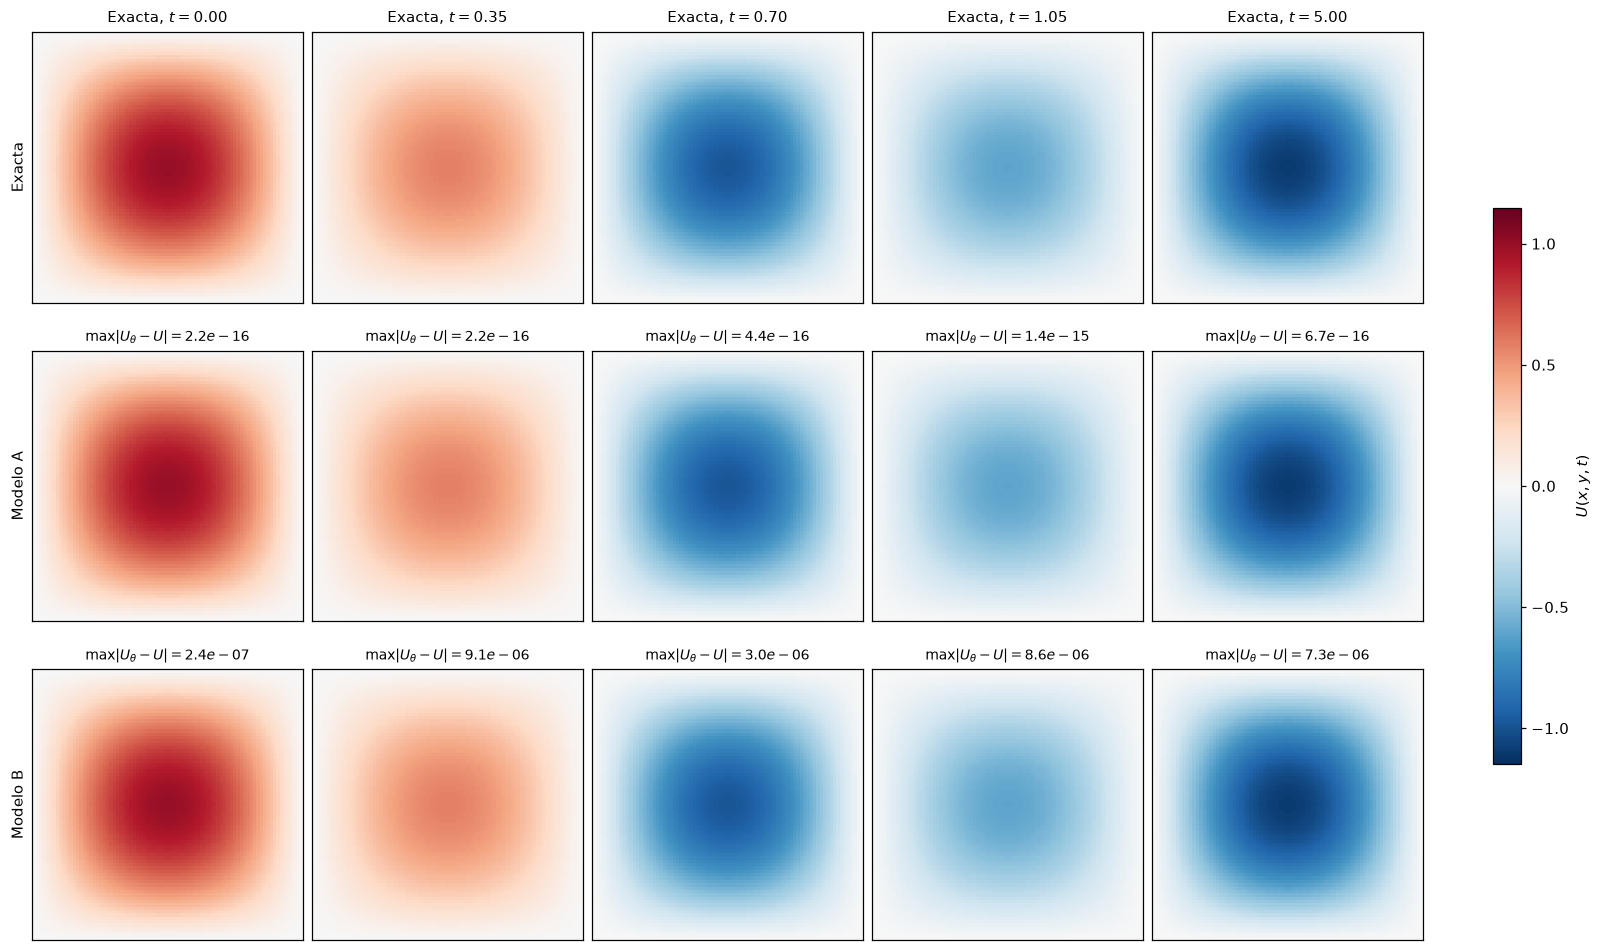

In [3]:
graficos.comparar_amplitudes(T_PRUEBA, membrana, evaluadores, T)
graficos.mapas_campo(evaluadores, tiempos=[0.0, 0.35, 0.7, 1.05, 5.0])
plt.show()

**Análisis.** Ambas soluciones son indistinguibles de la analítica a simple vista, también en $t=5$, fuera de la ventana de colocación. Ahora, como
$$
U_\theta-U=\phi(x,y)\left[a_\theta(t)-a(t)\right]=\phi(x,y)\,e(t),
$$
el error del campo siempre tiene la forma del modo $(1,1)$ y su máximo es $|e(t)|$. Por tanto, basta cuantificar el error de la amplitud. Se puede ver que el error del Modelo A es ruido de redondeo, mientras que el del Modelo B oscila con amplitud $\sim10^{-5}$ y su envolvente crece fuera de $[0,T]$.

### 3. Errores de aproximación

Ahora, sobre una malla uniforme de $2001$ puntos, por separado en $I=[0,T]$ y en $I=(T,2T]$, calculamos el error $L^2$ relativo $\|e\|_{L^2}/\|a\|_{L^2}$, el error máximo $\max|e|$, el error cuadrático medio, el residuo RMS $\sqrt{\overline{r_\theta^2}}$ y el error $L^2$ del campo,
$$
\|U_\theta-U\|_{L^2([0,1]^2\times I)}=\frac12\|e\|_{L^2(I)},
$$
pues $\int_0^1\!\!\int_0^1\phi^2\,dx\,dy=\frac14$.

In [4]:
t_in, t_out = np.linspace(0, T, 2001), np.linspace(T, 2 * T, 2001)
filas = {}
for n, ev in evaluadores.items():
    filas[f"{n} [0,T]"] = ev.metricas(t_in).como_dict()
    filas[f"{n} (T,2T]"] = ev.metricas(t_out).como_dict()
print(tabla(filas))

c = abs(w2)
print(f"\nModelo B: residuo RMS predicho  kappa^2 R c^2 / (3 sqrt 2) = {membrana.kappa2 * R * c**2 / (3 * np.sqrt(2)):.4e}   (c = |omega_2| = {c:.5f})")
print(f"          residuo RMS medido                              = {evaluadores['Modelo B'].metricas(t_in).residuo_rms:.4e}")

                    l2_relativo          linf          rmse      l2_campo   residuo_rms
---------------------------------------------------------------------------------------
Modelo A [0,T]        8.503e-16     1.749e-15     7.072e-16     6.126e-16     2.193e-15
Modelo A (T,2T]       1.291e-15     1.762e-15     1.057e-15     9.151e-16     2.519e-15
Modelo B [0,T]        5.576e-06     9.179e-06     4.638e-06     4.017e-06     3.264e-04
Modelo B (T,2T]       1.059e-05     1.757e-05     8.664e-06     7.504e-06     3.257e-04

Modelo B: residuo RMS predicho  kappa^2 R c^2 / (3 sqrt 2) = 3.2584e-04   (c = |omega_2| = 0.00781)
          residuo RMS medido                              = 3.2643e-04


**Análisis de los errores.**

Para el Modelo A, los errores son $\sim10^{-15}$ dentro y fuera de la ventana de colocación. Es decir, como la clase de funciones del Modelo A contiene a la solución exacta y el optimizador la encuentra, los errores de aproximación y de optimización son nulos, y la extrapolación es exacta.

Por su parte, en el Modelo B los errores son $\sim10^{-5}$ y no disminuyen con más iteraciones, porque vienen de la arquitectura. Para verlo, tomemos $b_2\in\{0,\pi\}$ y $c=|\omega_2|\ll1$. Entonces,
$$
A\sin(\omega_2h_1+b_2)\approx R_\theta\left(h_1-\frac{c^2}{6}h_1^3\right),\qquad R_\theta=A\,\omega_2\cos b_2,
$$
y usando $h_1^3=\frac{3\sin\vartheta-\sin3\vartheta}{4}$, con $\vartheta=\omega_1t+b_1$,
$$
a_\theta\approx R_\theta\left(1-\frac{c^2}{8}\right)\sin\vartheta+\frac{R_\theta c^2}{24}\sin3\vartheta.
$$
Ahora, el primer armónico cumple la EDO con $\omega_1=\kappa$, pero el tercero no:
$$
r_B\approx(\kappa^2-9\kappa^2)\frac{R_\theta c^2}{24}\sin3\vartheta
\Rightarrow
\boxed{r_B\approx-\frac{\kappa^2R_\theta c^2}{3}\sin3\vartheta}
$$
cuyo valor RMS predicho, $\kappa^2Rc^2/(3\sqrt2)=3.258\times10^{-4}$, coincide con el medido, $3.264\times10^{-4}$, con un error del $0.2\%$. Así, como $r_B\neq0$ para todo $c>0$, y sólo tiende a cero cuando $c\to0$ con $A=R/c\to\infty$, la pérdida no alcanza su ínfimo $0$ con parámetros finitos, y el optimizador se detiene sobre ese valle en $c\approx0.008$.

Por último, el error del Modelo B se duplica en $(T,2T]$. Esto es porque, al compensar el tercer armónico, el optimizador desplaza levemente la frecuencia ($\omega_1-\kappa\approx3.5\times10^{-6}$), y ese desfase se acumula linealmente en $t$.

### 4. Conservación de la energía mecánica

Ahora, sustituyendo $U_\theta=\phi\,a_\theta$ en la integral de la ayuda, con $\int_0^1\!\!\int_0^1\phi^2\,dx\,dy=\frac14$ y $\int_0^1\!\!\int_0^1\left(\phi_x^2+\phi_y^2\right)dx\,dy=\frac{\pi^2}{2}$, tenemos
$$
E_\theta(t)=\frac12\left[\frac14a_\theta'^2+\frac{\pi^2}{2}a_\theta^2\right]
\Rightarrow
\boxed{E_\theta(t)=\frac18\left[a_\theta'(t)^2+\kappa^2a_\theta(t)^2\right]}
$$
Entonces, derivando respecto al tiempo,
$$
\frac{dE_\theta}{dt}=\frac18\left[2a_\theta'a_\theta''+2\kappa^2a_\theta a_\theta'\right]
\Rightarrow
\boxed{\frac{dE_\theta}{dt}=\frac14\,a_\theta'(t)\,r_\theta(t)}
$$
Es decir, la energía de la PINN se conserva si y sólo si su residuo físico es nulo (donde $a_\theta'\neq0$). Para la solución exacta, $E_0=\frac18(v_0^2+\kappa^2)=\frac{\pi(1+\pi)}{4}$.

Comparamos la primera expresión con la integral doble de la ayuda calculada por cuadratura de Simpson ($101\times101$ puntos), y la segunda con la derivada numérica de $E_\theta$.

E0 = pi (1 + pi) / 4 = 3.252799
Modelo A: max|E_reducida - E_cuadratura| = 4.4e-16,  max|E - E0|/E0 en [0, 2T] = 8.19e-16
Modelo B: max|E_reducida - E_cuadratura| = 8.9e-16,  max|E - E0|/E0 en [0, 2T] = 2.51e-05


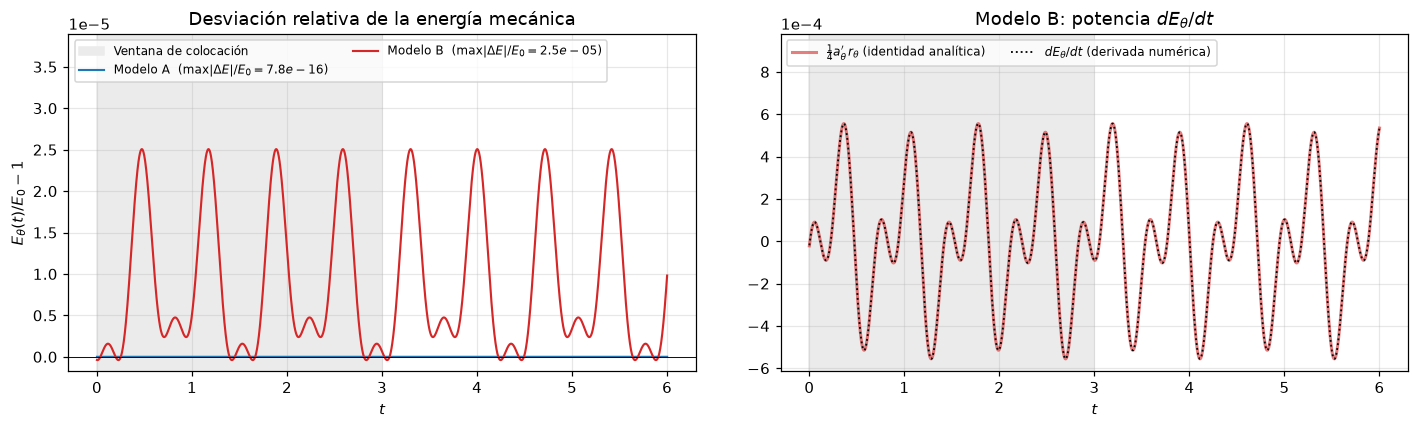

Modelo A: max|E - E0|/E0 en [0, 100] = 9.56e-16,  max|e| en [90, 100] = 1.09e-14
Modelo B: max|E - E0|/E0 en [0, 100] = 2.51e-05,  max|e| en [90, 100] = 3.89e-04


In [5]:
E0 = membrana.energia_inicial
print(f"E0 = pi (1 + pi) / 4 = {E0:.6f}")
t_E = np.linspace(0, 2 * T, 9)
for n, ev in evaluadores.items():
    d = np.max(np.abs(ev.energia(t_E) - ev.energia_cuadratura(t_E)))
    print(f"{n}: max|E_reducida - E_cuadratura| = {d:.1e},  max|E - E0|/E0 en [0, 2T] = {ev.deriva_energia(T_PRUEBA):.2e}")

graficos.energia(T_PRUEBA, evaluadores, T)
plt.show()

t_largo = np.linspace(0, 100, 50001)
for n, ev in evaluadores.items():
    print(f"{n}: max|E - E0|/E0 en [0, 100] = {ev.deriva_energia(t_largo):.2e},  "
          f"max|e| en [90, 100] = {np.max(np.abs(ev.error_amplitud(t_largo[t_largo > 90]))):.2e}")

**Análisis de la energía.**

Lo primero que vemos es que la expresión $E_\theta=\frac18(a_\theta'^2+\kappa^2a_\theta^2)$ coincide con la integral de la ayuda a precisión de máquina, y que la potencia $\frac14a_\theta'r_\theta$ coincide con la derivada numérica de $E_\theta$ (panel derecho).

Para el Modelo A, $|E_\theta-E_0|/E_0\sim10^{-15}$ hasta $t=100$: la energía se conserva a precisión de máquina porque $r_A\equiv0$.

Por su parte, en el Modelo B la energía no se conserva exactamente, sino que oscila con amplitud relativa $2.5\times10^{-5}$. Como $r_B\propto\sin3\vartheta$ y $a_\theta'\propto\cos\vartheta$,
$$
\frac{dE_\theta}{dt}\propto\cos\vartheta\,\sin3\vartheta=\frac12\left(\sin2\vartheta+\sin4\vartheta\right),
$$
cuyo promedio temporal es nulo. Por eso la energía oscila con frecuencias $2\omega$ y $4\omega$ sin deriva secular: en $t=100$ la desviación sigue siendo $2.5\times10^{-5}$, mientras que el error de la trayectoria crece hasta $4\times10^{-4}$ por el desfase. Es decir, una energía acotada no garantiza una trayectoria correcta, pues un desfase no cambia la energía.

## Conclusiones

Ambas PINN imponen las condiciones de borde de forma exacta, y la pérdida $\mathcal L(\theta)$, minimizada con Adam y L-BFGS desde varias inicializaciones, impone la ecuación y las condiciones iniciales.

Ahora, el Modelo A recupera exactamente la solución analítica: errores $\sim10^{-15}$, extrapolación exacta y energía conservada a precisión de máquina. Por su parte, el Modelo B aproxima la solución con un error $\sim10^{-5}$ que no se puede reducir, porque la composición $\sin(\omega_2\sin(\cdot))$ genera un tercer armónico, y la pérdida sólo se anula en el límite $\omega_2\to0$, $A\to\infty$. Su energía oscila en $2.5\times10^{-5}$ sin deriva, mientras que su error de fase crece al extrapolar. Además, la solución trivial $a_\theta\approx0$ y varios mínimos locales dificultan su entrenamiento.

Por tanto, la arquitectura poco profunda, cuya clase contiene a la solución física, supera a la composición de dos capas. Es decir, lo que determina la calidad de la PINN es el sesgo inductivo de la arquitectura, no su profundidad.